In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys

sys.path.append("../")

import geopandas as gpd
import contextily as ctx
import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf
import urllib.request
import zipfile

In [2]:
URL = "https://api.insee.fr/melodi/file/DS_RP_EMPLOI_LR_COMP/DS_RP_EMPLOI_LR_COMP_2023_CSV_FR"
urllib.request.urlretrieve(URL, "emploi.zip")

with zipfile.ZipFile("emploi.zip") as z:
    with z.open("DS_RP_EMPLOI_LR_COMP_2023_data.csv") as f:
        emploi = pd.read_csv(f, sep=";", dtype={"GEO": str, "EMPSTA_ENQ": str})

In [3]:
emploi = emploi [['TIME_PERIOD','EMPSTA_ENQ','GEO_OBJECT','GEO','OBS_VALUE','PCS']]

emploi_dep = emploi.loc[emploi["GEO_OBJECT"] == "DEP"]
emploi_dep = emploi_dep.loc[emploi_dep["PCS"] == "_T"]
emploi_dep = emploi_dep.loc[emploi_dep["TIME_PERIOD"] == 2023]

emploi_dep = emploi_dep.pivot(index=["GEO"], columns="EMPSTA_ENQ", values="OBS_VALUE")
emploi_dep.head()


EMPSTA_ENQ,1,1T2,2
GEO,,,
01,306353.92376,332062.20638,25708.28261
02,198151.87740,227038.54348,28886.66608
03,124010.40923,138249.81493,14239.40570
04,64198.24881,71219.69936,7021.45055
05,59286.34693,64156.11979,4869.77287


Le jeu provient de : https://www.data.gouv.fr/datasets/population-active-et-chomage-principaux-indicateurs-dossier-complet-1

In [6]:
emploi_dep["Taux d'activité"]=emploi_dep["1"]/emploi_dep['1T2']

emploi_dep= emploi_dep.drop(columns=["1","2"])
emploi_dep=emploi_dep.reset_index()

emploi_dep.columns.tolist()

emploi_dep=emploi_dep.rename(columns = {"1T2":"Population active","GEO":"Département"})
emploi_dep.head()


EMPSTA_ENQ,Département,PCS,Population active,Taux d'activité
0,01,1,2863.11774,0.998315
1,01,2,22439.73589,0.959634
2,01,3,56516.54738,0.966074
3,01,4,89808.06197,0.948849
4,01,5,84144.48420,0.891198


In [ ]:
emploi_dep.sort_values(by="Taux d'activité").head()

EMPSTA_ENQ,Département,Population active,Taux d'activité
99,974,376034.03759,0.787271
96,971,157368.88831,0.820405
66,66,198806.49500,0.852335
97,972,152661.14323,0.856454
98,973,92071.64531,0.860825


In [6]:
URL = "https://data.education.gouv.fr/api/explore/v2.1/catalog/datasets/fr-en-indicateurs-de-resultat-des-lycees-denseignement-general-et-technologique/exports/csv?use_labels=true"
bac = pd.read_csv(URL,sep=";",low_memory=False)

Les données de bac proviennent de : https://www.data.gouv.fr/datasets/indicateurs-de-valeur-ajoutee-des-lycees-denseignement-general-et-technologique-ancienne-version 

In [7]:


bac["Nombre de réussites"] = bac["Presents - Toutes series"]*bac["Taux de reussite - Toutes series"]/100
bac["Nombre de mentions"] = bac["Presents - Toutes series"]*bac["Taux de mentions - Toutes series"]/100
bac["Nombre acces 2nde-bac pondéré"] = bac["Taux d'acces 2nde-bac"]*bac["Presents - Toutes series"]/100

bac = bac.groupby(["Code departement","Annee"]).agg({"Presents - Toutes series":"sum",
                                               "Effectif de seconde":"sum",
                                               "Effectif de premiere":"sum",
                                               "Effectif de terminale":"sum",
                                               "Nombre de réussites":"sum",
                                               "Nombre de mentions":"sum",
                                               "Nombre acces 2nde-bac pondéré":"sum"})

bac["Taux de réussite"] = bac["Nombre de réussites"]/bac["Presents - Toutes series"]
bac["Taux de mentions"] = bac["Nombre de mentions"]/bac["Presents - Toutes series"]
bac["Taux de passage 2nde - bac"] = bac["Nombre acces 2nde-bac pondéré"]/bac["Presents - Toutes series"]

bac = bac.drop(columns = ["Nombre de réussites","Nombre de mentions","Nombre acces 2nde-bac pondéré"])

bac= bac.reset_index()
bac.head()

,Code departement,Annee,Presents - Toutes series,Effectif de seconde,Effectif de premiere,Effectif de terminale,Taux de réussite,Taux de mentions,Taux de passage 2nde - bac
0,01,2012,3628,4383.0,3688.0,0.0,0.915474,0.0,0.737643
1,01,2013,3665,4495.0,3926.0,0.0,0.937465,0.0,0.758963
2,01,2014,3577,4601.0,4074.0,0.0,0.932586,0.0,0.763229
3,01,2015,3852,4893.0,4185.0,4083.0,0.934772,0.0,0.780132
4,01,2016,4035,4736.0,4528.0,4261.0,0.923244,0.0,0.772491


In [7]:
bac_2023 = bac[bac["Annee"]==2023]

bac_2023.head()

,Code departement,Annee,Presents - Toutes series,Effectif de seconde,Effectif de premiere,Effectif de terminale,Taux de réussite,Taux de mentions,Taux de passage 2nde - bac
11,01,2023,4713,5085.0,4679.0,4804.0,0.947836,0.606446,0.843747
23,02,2023,3388,3801.0,3476.0,3450.0,0.933999,0.546975,0.826077
35,03,2023,1951,2123.0,1855.0,2034.0,0.950661,0.559047,0.833203
47,04,2023,1119,1244.0,1216.0,1159.0,0.956622,0.617784,0.843512
59,05,2023,912,1031.0,971.0,971.0,0.978662,0.719638,0.861974


In [8]:
bac_emploi_2023 = bac_2023.merge(
    emploi_dep,
    left_on = ["Code departement"],
  right_on = ["Département"],
  how = "left"
)

bac_emploi_2023 = bac_emploi_2023.dropna()

bac_emploi_2023.head()

,Code departement,Annee,Presents - Toutes series,Effectif de seconde,Effectif de premiere,Effectif de terminale,Taux de réussite,Taux de mentions,Taux de passage 2nde - bac,Département,Population active,Taux d'activité
0,01,2023,4713,5085.0,4679.0,4804.0,0.947836,0.606446,0.843747,01,332062.20638,0.922580
1,02,2023,3388,3801.0,3476.0,3450.0,0.933999,0.546975,0.826077,02,227038.54348,0.872768
2,03,2023,1951,2123.0,1855.0,2034.0,0.950661,0.559047,0.833203,03,138249.81493,0.897002
3,04,2023,1119,1244.0,1216.0,1159.0,0.956622,0.617784,0.843512,04,71219.69936,0.901411
4,05,2023,912,1031.0,971.0,971.0,0.978662,0.719638,0.861974,05,64156.11979,0.924095


Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de réussite au baccalauréat par département - 2023")

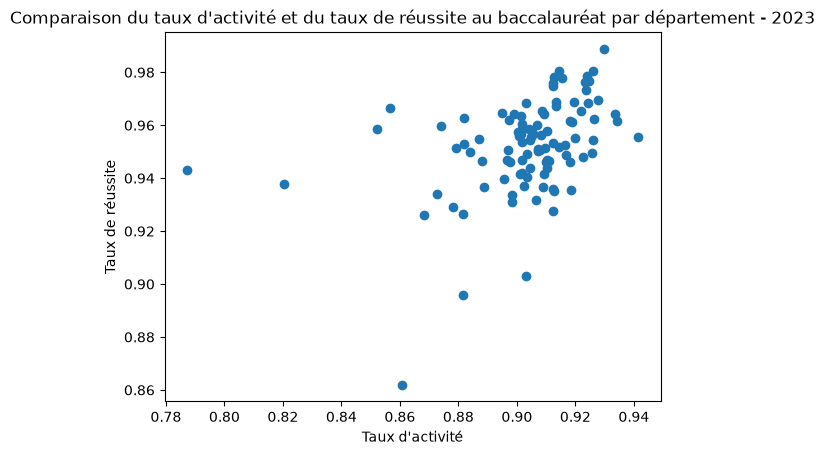

In [9]:
plt.scatter(bac_emploi_2023["Taux d'activité"],bac_emploi_2023["Taux de réussite"])
plt.xlabel("Taux d'activité")
plt.ylabel("Taux de réussite")
plt.title("Comparaison du taux d'activité et du taux de réussite au baccalauréat par département - 2023")

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de réussite")   R-squared:                       0.158
Model:                               OLS   Adj. R-squared:                  0.150
Method:                    Least Squares   F-statistic:                     18.44
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):           4.13e-05
Time:                           17:12:52   Log-Likelihood:                 268.61
No. Observations:                    100   AIC:                            -533.2
Df Residuals:                         98   BIC:                            -528.0
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
In

Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de réussite au baccalauréat par département - 2023")

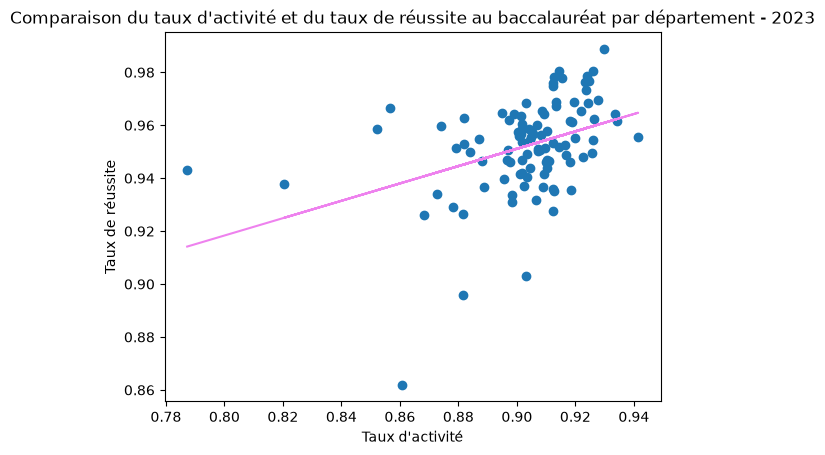

In [ ]:
results = smf.ols('Q("Taux de réussite") ~ Q("Taux d\'activité")', data=bac_emploi_2023).fit()
print(results.summary())

#l'IA m'a aidée dans la production d'une régression

plt.scatter (bac_emploi_2023["Taux d'activité"],bac_emploi_2023["Taux de réussite"])
plt.plot(
    bac_emploi_2023["Taux d'activité"],
    results.fittedvalues,
    color="violet",
    label="Droite de régression"
)
plt.xlabel("Taux d'activité")
plt.ylabel("Taux de réussite")
plt.title("Comparaison du taux d'activité et du taux de réussite au baccalauréat par département - 2023")

Le résultat est plus concluant qu'au niveau académie. 

Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de passage 2nde-bac au baccalauréat par département - 2023")

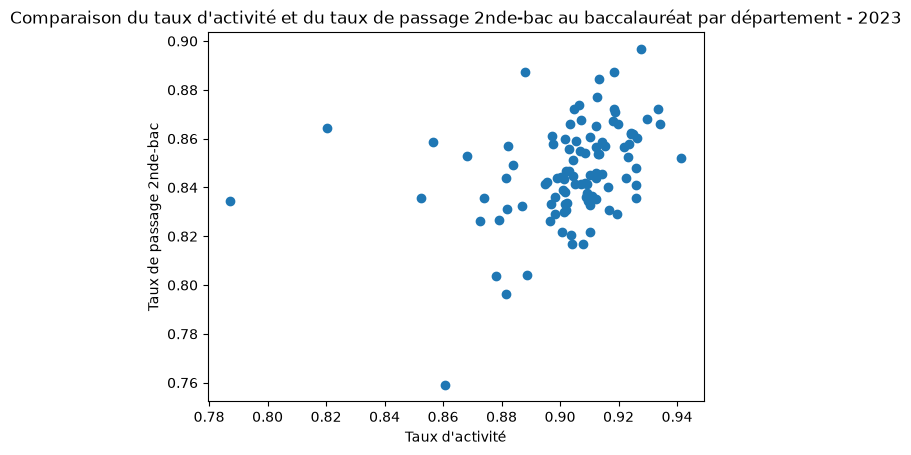

In [11]:
plt.scatter(bac_emploi_2023["Taux d'activité"],bac_emploi_2023["Taux de passage 2nde - bac"])
plt.xlabel("Taux d'activité")
plt.ylabel("Taux de passage 2nde-bac")
plt.title("Comparaison du taux d'activité et du taux de passage 2nde-bac au baccalauréat par département - 2023")

On teste de comparer le taux d'activité au nombre de mentions.

Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de mentions au baccalauréat par département- 2023")

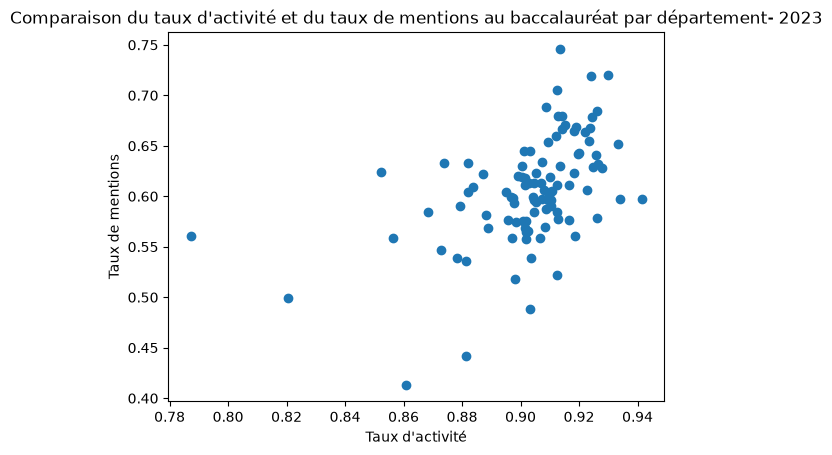

In [12]:
plt.scatter(bac_emploi_2023["Taux d'activité"],bac_emploi_2023["Taux de mentions"])
plt.xlabel("Taux d'activité")
plt.ylabel("Taux de mentions")
plt.title("Comparaison du taux d'activité et du taux de mentions au baccalauréat par département- 2023")

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de mentions")   R-squared:                       0.231
Model:                               OLS   Adj. R-squared:                  0.223
Method:                    Least Squares   F-statistic:                     29.45
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):           4.16e-07
Time:                           17:12:52   Log-Likelihood:                 164.63
No. Observations:                    100   AIC:                            -325.3
Df Residuals:                         98   BIC:                            -320.0
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
In

Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de mentions au baccalauréat par département- 2023")

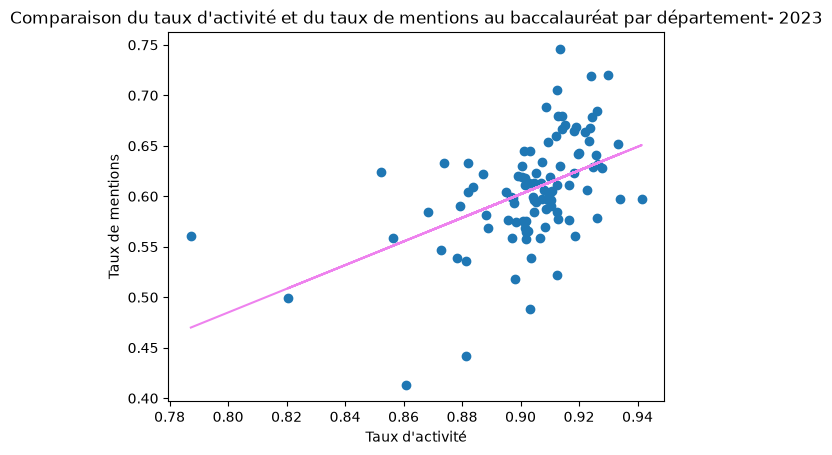

In [13]:
results = smf.ols('Q("Taux de mentions") ~ Q("Taux d\'activité")', data=bac_emploi_2023).fit()
print(results.summary())

plt.scatter (bac_emploi_2023["Taux d'activité"],bac_emploi_2023["Taux de mentions"])
plt.plot(
    bac_emploi_2023["Taux d'activité"],
    results.fittedvalues,
    color="violet",
    label="Droite de régression"
)
plt.xlabel("Taux d'activité")
plt.ylabel("Taux de mentions")
plt.title("Comparaison du taux d'activité et du taux de mentions au baccalauréat par département- 2023")

Le résultat est assez similaire.

On se penche désormais sur les données d'inscrits au RSA, également présentes sur le site data.gouv.
On le nettoie pour garder les données intéressantes et le rendre plus facile à manipuler. On reprend l'année 2023, on prend le 1er janvier arbitrairement.

Les données sont disponibles ici : https://www.data.gouv.fr/datasets/rsa-et-pa-repartition-des-allocataires-selon-lage-departement 

In [9]:
URL = "https://data.caf.fr/api/explore/v2.1/catalog/datasets/rsa_ppa_s_agg_age_5_dep/exports/csv?use_labels=true"

rsa = pd.read_csv(URL, sep=";")

In [10]:
rsa= pd.read_csv("../rsa_ppa_s_agg_age_5_dep.csv",sep=";")

rsa=rsa[rsa["Date référence"]=="2023-01-01"]

rsa= rsa.drop(columns=["Nom département","Numéro région","Nom région","Lieu résidence","Date référence"])

rsa =rsa.groupby(["Numéro département","RSA ou PPA"]).agg({"Nombre foyers RSA_PPA":"sum", 
                                                           "Nombre personnes RSA_PPA":"sum"})
rsa = rsa.reset_index()

rsa= rsa[rsa["RSA ou PPA"].isin(["RSA et PA","RSA seul"])]

rsa=rsa.groupby(["Numéro département"]).agg({"Nombre foyers RSA_PPA":"sum", 
                                            "Nombre personnes RSA_PPA":"sum"})
rsa=rsa.reset_index()
rsa.head()

,Numéro département,Nombre foyers RSA_PPA,Nombre personnes RSA_PPA
0,01,7679,15588
1,02,17363,38572
2,03,9794,20099
3,04,4121,7880
4,05,3013,5410


Pour obtenir un taux afin d'augmenter la comparabilité entre des académie de population différente, on rapproche ces données du fichier emploi, où on avait la donnée de population active.

In [15]:
rsa_bac= rsa.merge(
     bac_emploi_2023,
  left_on = ["Numéro département"],
  right_on = ["Code departement"],
  how = "left" 
)

rsa_bac ["Nombre personnes bénéficiant du RSA par actif"]=rsa_bac["Nombre personnes RSA_PPA"]/rsa_bac["Population active"]
rsa_bac.tail(80)

,Numéro département,Nombre foyers RSA_PPA,Nombre personnes RSA_PPA,Code departement,Annee,Presents - Toutes series,Effectif de seconde,Effectif de premiere,Effectif de terminale,Taux de réussite,Taux de mentions,Taux de passage 2nde - bac,Département,Population active,Taux d'activité,Nombre personnes bénéficiant du RSA par actif
24,26,10559,21268,26,2023.0,3921.0,4310.0,4018.0,4127.0,0.945983,0.593754,0.857623,26,236923.11488,0.897704,0.089768
25,27,13274,28485,27,2023.0,3929.0,4556.0,4036.0,3870.0,0.946701,0.557692,0.846541,27,274919.07817,0.901918,0.103612
26,28,8413,17449,28,2023.0,3267.0,3353.0,3052.0,3285.0,0.950787,0.606373,0.816762,28,198243.50290,0.907905,0.088018
27,29,16309,29418,29,2023.0,6618.0,6987.0,6737.0,6978.0,0.978377,0.679178,0.853540,29,415287.30425,0.912799,0.070838
28,2A,2517,4305,2A,2023.0,974.0,1081.0,948.0,1052.0,0.969415,0.627649,0.896869,2A,75170.48716,0.927765,0.057270
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,974,95128,216251,974,2023.0,8097.0,8919.0,8178.0,8078.0,0.942920,0.561129,0.834502,974,376034.03759,0.787271,0.575084
100,976,4095,11579,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
101,978,2141,4734,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
102,99,149,327,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Text(0.5, 1.0, 'Comparaison du taux de bénéficiaires du RSA et du taux de réussite au baccalauréat par département - 2023')

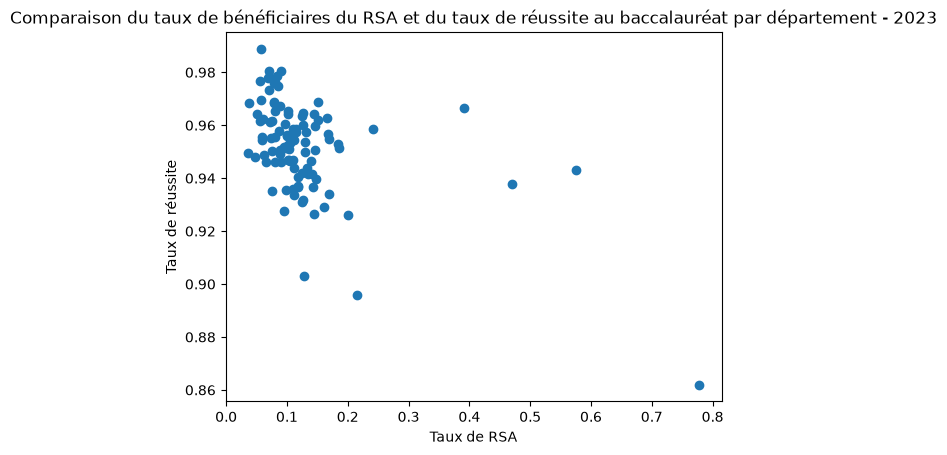

In [16]:
plt.scatter(rsa_bac["Nombre personnes bénéficiant du RSA par actif"],rsa_bac["Taux de réussite"])
plt.xlabel("Taux de RSA")
plt.ylabel("Taux de réussite")
plt.title("Comparaison du taux de bénéficiaires du RSA et du taux de réussite au baccalauréat par département - 2023")

On voudrait retirer les valeurs extrêmes. On tente de se concentrer sur la France métropolitaine.

In [17]:
rsa_bac_metropole = rsa_bac[~rsa_bac["Numéro département"].isin(["971", "972", "973", "974", "976","99","978","XX"])]
rsa_bac_metropole.tail()

,Numéro département,Nombre foyers RSA_PPA,Nombre personnes RSA_PPA,Code departement,Annee,Presents - Toutes series,Effectif de seconde,Effectif de premiere,Effectif de terminale,Taux de réussite,Taux de mentions,Taux de passage 2nde - bac,Département,Population active,Taux d'activité,Nombre personnes bénéficiant du RSA par actif
91,91,30011,64055,91,2023.0,12552.0,13422.0,12602.0,12783.0,0.935457,0.561017,0.872008,91,645628.21566,0.918461,0.099213
92,92,31599,56895,92,2023.0,13703.0,14815.0,14301.0,14066.0,0.945994,0.664322,0.887483,92,866299.62267,0.918271,0.065676
93,93,80835,170497,93,2023.0,14152.0,14973.0,13739.0,14345.0,0.895953,0.441321,0.843762,93,794200.32671,0.881435,0.214678
94,94,46169,89069,94,2023.0,11147.0,11889.0,11369.0,11626.0,0.931654,0.559114,0.873879,94,703774.25519,0.906506,0.126559
95,95,36241,77793,95,2023.0,12384.0,13016.0,12498.0,13008.0,0.903218,0.487978,0.855738,95,609574.93629,0.903154,0.127618


Text(0.5, 1.0, 'Comparaison du taux de bénéficiaires du RSA et du taux de réussite au baccalauréat par département métropolitain - 2023')

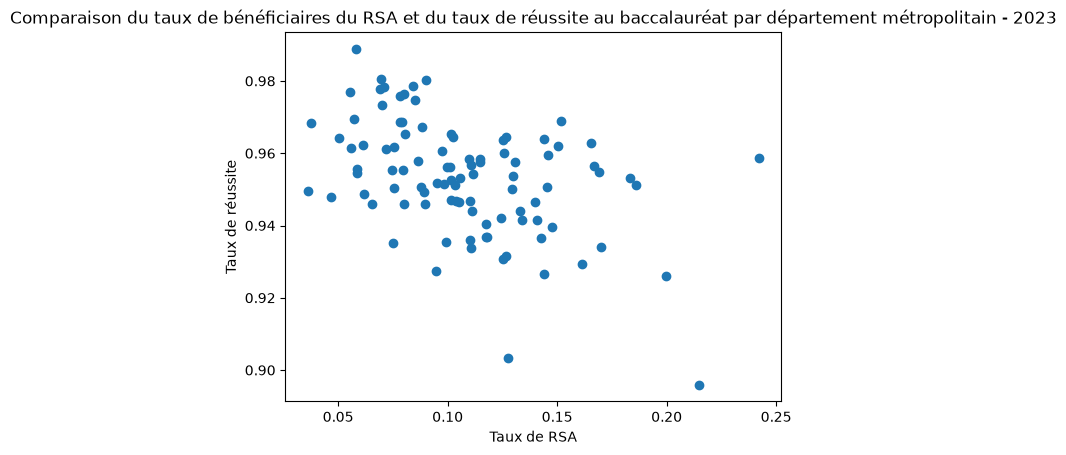

In [18]:

plt.scatter(rsa_bac_metropole["Nombre personnes bénéficiant du RSA par actif"],rsa_bac_metropole["Taux de réussite"])
plt.xlabel("Taux de RSA")
plt.ylabel("Taux de réussite")
plt.title("Comparaison du taux de bénéficiaires du RSA et du taux de réussite au baccalauréat par département métropolitain - 2023")

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de réussite")   R-squared:                       0.197
Model:                               OLS   Adj. R-squared:                  0.188
Method:                    Least Squares   F-statistic:                     23.04
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):           5.98e-06
Time:                           17:12:54   Log-Likelihood:                 273.32
No. Observations:                     96   AIC:                            -542.6
Df Residuals:                         94   BIC:                            -537.5
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                                                         coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------

Text(0.5, 1.0, 'Comparaison du taux de bénéficiaires du RSA et du taux de réussite au baccalauréat par département métropolitain - 2023')

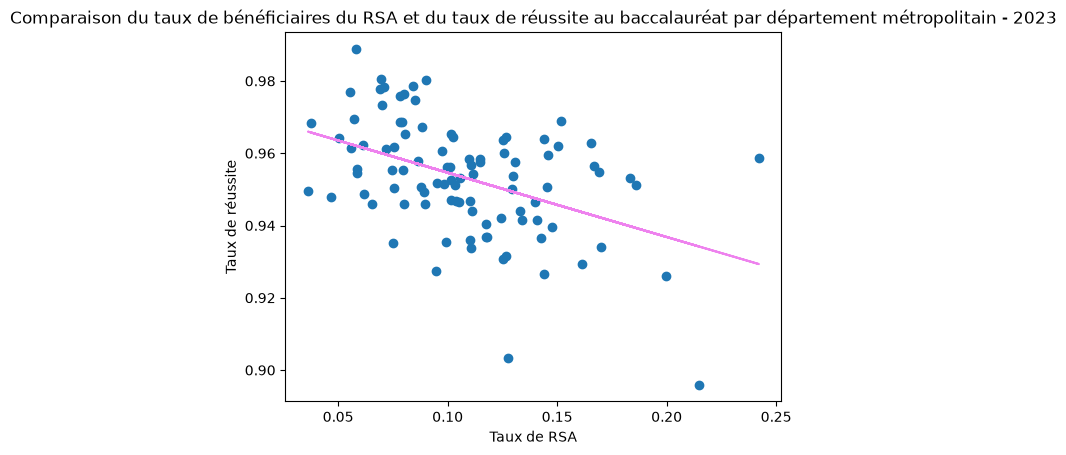

In [19]:
results = smf.ols('Q("Taux de réussite") ~ Q("Nombre personnes bénéficiant du RSA par actif")', data=rsa_bac_metropole).fit()
print(results.summary())

plt.scatter(rsa_bac_metropole["Nombre personnes bénéficiant du RSA par actif"],rsa_bac_metropole["Taux de réussite"])
plt.plot(
    rsa_bac_metropole["Nombre personnes bénéficiant du RSA par actif"],
    results.fittedvalues,
    color="violet",
    label="Droite de régression"
)
plt.xlabel("Taux de RSA")
plt.ylabel("Taux de réussite")
plt.title("Comparaison du taux de bénéficiaires du RSA et du taux de réussite au baccalauréat par département métropolitain - 2023")

Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de mentions au baccalauréat par département métropolitain - 2023")

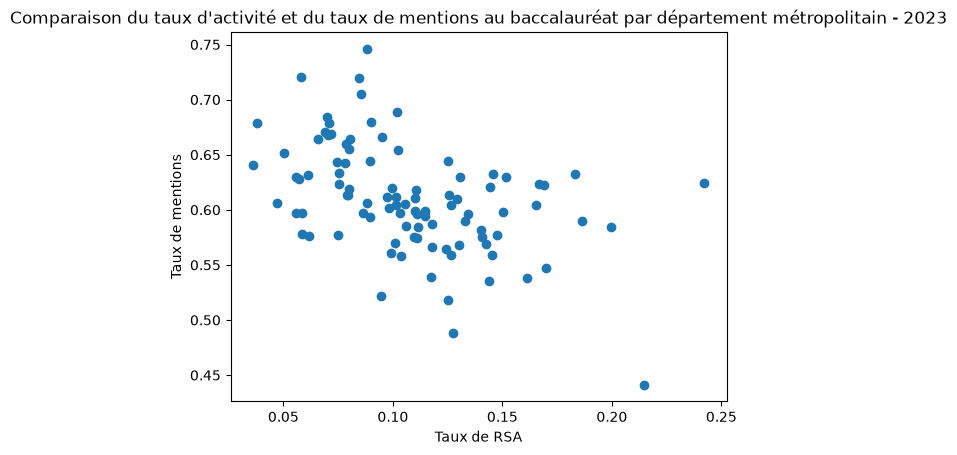

In [20]:
plt.scatter(rsa_bac_metropole["Nombre personnes bénéficiant du RSA par actif"],rsa_bac_metropole["Taux de mentions"])
plt.xlabel("Taux de RSA")
plt.ylabel("Taux de mentions")
plt.title("Comparaison du taux d'activité et du taux de mentions au baccalauréat par département métropolitain - 2023")

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de mentions")   R-squared:                       0.207
Model:                               OLS   Adj. R-squared:                  0.199
Method:                    Least Squares   F-statistic:                     24.55
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):           3.19e-06
Time:                           17:12:54   Log-Likelihood:                 164.87
No. Observations:                     96   AIC:                            -325.7
Df Residuals:                         94   BIC:                            -320.6
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                                                         coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------

Text(0.5, 1.0, 'Comparaison du taux de rsa et du taux de mentions au baccalauréat par département métropolitain - 2023')

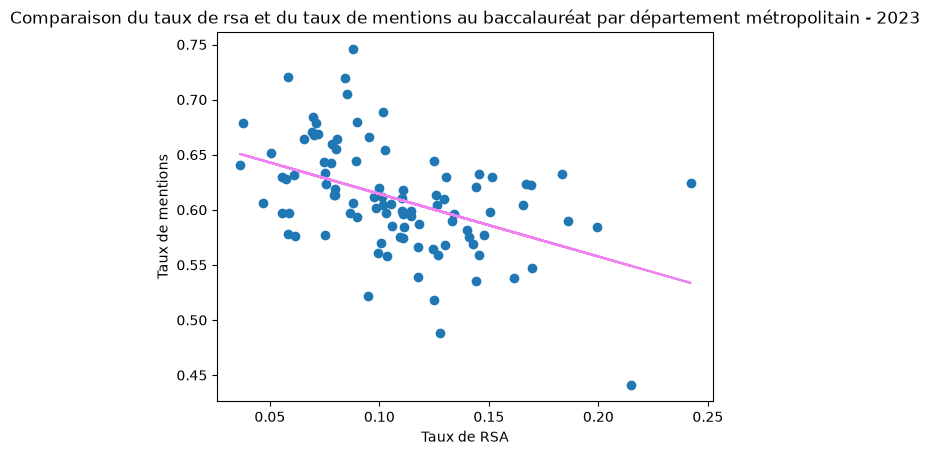

In [21]:
results = smf.ols('Q("Taux de mentions") ~ Q("Nombre personnes bénéficiant du RSA par actif")', data=rsa_bac_metropole).fit()
print(results.summary())

plt.scatter(rsa_bac_metropole["Nombre personnes bénéficiant du RSA par actif"],rsa_bac_metropole["Taux de mentions"])
plt.plot(
    rsa_bac_metropole["Nombre personnes bénéficiant du RSA par actif"],
    results.fittedvalues,
    color="violet",
    label="Droite de régression"
)

plt.xlabel("Taux de RSA")
plt.ylabel("Taux de mentions")
plt.title("Comparaison du taux de rsa et du taux de mentions au baccalauréat par département métropolitain - 2023")

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de réussite")   R-squared:                       0.185
Model:                               OLS   Adj. R-squared:                  0.176
Method:                    Least Squares   F-statistic:                     21.33
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):           1.23e-05
Time:                           17:21:07   Log-Likelihood:                 272.61
No. Observations:                     96   AIC:                            -541.2
Df Residuals:                         94   BIC:                            -536.1
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
In

Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de réussite au baccalauréat par département métropolitain - 2023")

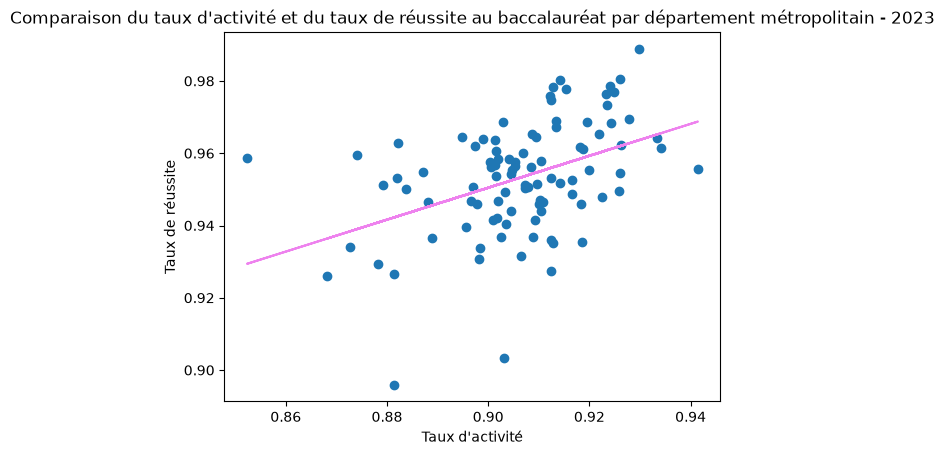

In [28]:
results = smf.ols(
    """Q("Taux de réussite") ~ Q("Taux d'activité")""",
    data=rsa_bac_metropole
).fit()

print(results.summary())

plt.scatter(rsa_bac_metropole["Taux d'activité"],rsa_bac_metropole["Taux de réussite"])
plt.plot(
    rsa_bac_metropole["Taux d'activité"],
    results.fittedvalues,
    color="violet",
    label="Droite de régression"
)

plt.xlabel("Taux d'activité")
plt.ylabel("Taux de réussite")
plt.title("Comparaison du taux d'activité et du taux de réussite au baccalauréat par département métropolitain - 2023")

In [23]:
rsa_bac_metropole.head()

,Numéro département,Nombre foyers RSA_PPA,Nombre personnes RSA_PPA,Code departement,Annee,Presents - Toutes series,Effectif de seconde,Effectif de premiere,Effectif de terminale,Taux de réussite,Taux de mentions,Taux de passage 2nde - bac,Département,Population active,Taux d'activité,Nombre personnes bénéficiant du RSA par actif
0,01,7679,15588,01,2023.0,4713.0,5085.0,4679.0,4804.0,0.947836,0.606446,0.843747,01,332062.20638,0.922580,0.046943
1,02,17363,38572,02,2023.0,3388.0,3801.0,3476.0,3450.0,0.933999,0.546975,0.826077,02,227038.54348,0.872768,0.169892
2,03,9794,20099,03,2023.0,1951.0,2123.0,1855.0,2034.0,0.950661,0.559047,0.833203,03,138249.81493,0.897002,0.145382
3,04,4121,7880,04,2023.0,1119.0,1244.0,1216.0,1159.0,0.956622,0.617784,0.843512,04,71219.69936,0.901411,0.110644
4,05,3013,5410,05,2023.0,912.0,1031.0,971.0,971.0,0.978662,0.719638,0.861974,05,64156.11979,0.924095,0.084326


                              OLS Regression Results                             
Dep. Variable:     Q("Taux de mentions")   R-squared:                       0.177
Model:                               OLS   Adj. R-squared:                  0.168
Method:                    Least Squares   F-statistic:                     20.25
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):           1.95e-05
Time:                           17:20:24   Log-Likelihood:                 163.09
No. Observations:                     96   AIC:                            -322.2
Df Residuals:                         94   BIC:                            -317.1
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
In

Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de mentions au baccalauréat par département métropolitain - 2023")

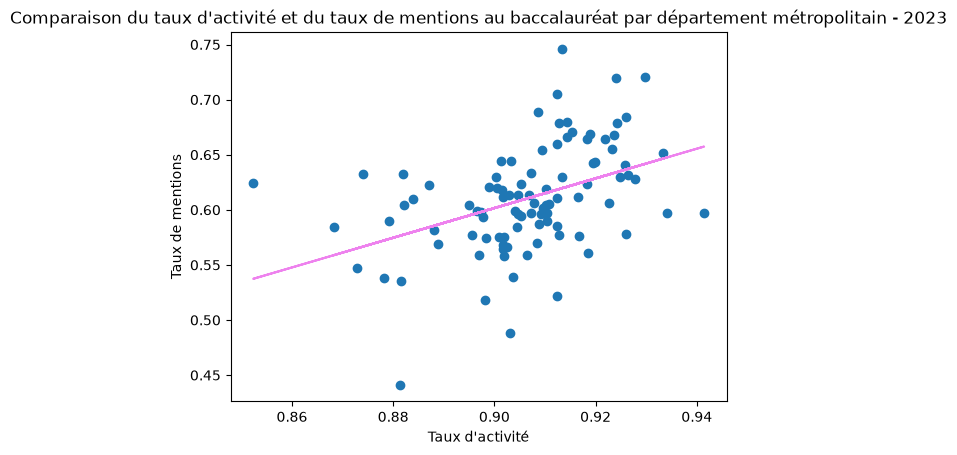

In [27]:
results = smf.ols(
    """Q("Taux de mentions") ~ Q("Taux d'activité")""",
    data=rsa_bac_metropole
).fit()

print(results.summary())

plt.scatter(rsa_bac_metropole["Taux d'activité"],rsa_bac_metropole["Taux de mentions"])
plt.plot(
    rsa_bac_metropole["Taux d'activité"],
    results.fittedvalues,
    color="violet",
    label="Droite de régression"
)

plt.xlabel("Taux d'activité")
plt.ylabel("Taux de mentions")
plt.title("Comparaison du taux d'activité et du taux de mentions au baccalauréat par département métropolitain - 2023")

In [24]:
from cartiflette import carti_download

france = carti_download(
      values = ["France"],
      crs = 4326,
      borders = "DEPARTEMENT",
      vectorfile_format="geojson",
      simplification=50,
      filter_by="FRANCE_ENTIERE",
      source="EXPRESS-COG-CARTO-TERRITOIRE",
      year=2022)

france_metro = france[~france['INSEE_DEP'].isin(["971","972","973","974","976"])]

france_metro = france_metro.merge(rsa_bac,
      left_on = ["INSEE_DEP"],
      right_on = ["Code departement"],
      how = "left" 
)
france_metro.head()


,INSEE_DEP,PAYS,LIBELLE_DEPARTEMENT,POPULATION,SOURCE,geometry,Numéro département,Nombre foyers RSA_PPA,Nombre personnes RSA_PPA,Code departement,...,Effectif de seconde,Effectif de premiere,Effectif de terminale,Taux de réussite,Taux de mentions,Taux de passage 2nde - bac,Département,Population active,Taux d'activité,Nombre personnes bénéficiant du RSA par actif
0,43,France,Haute-Loire,227570,IGN:EXPRESS-COG-CARTO-TERRITOIRE,"POLYGON ((3.89745 45.35699, 3.89691 45.35631, ...",43,2884,5718,43,...,1608.0,1549.0,1590.0,0.976859,0.629481,0.861913,43,102909.78352,0.924815,0.055563
1,65,France,Hautes-Pyrénées,229567,IGN:EXPRESS-COG-CARTO-TERRITOIRE,"MULTIPOLYGON (((-0.09705 43.5822, -0.09642 43....",65,5530,11143,65,...,1578.0,1523.0,1591.0,0.958458,0.599371,0.817002,65,97262.83671,0.904101,0.114566
2,29,France,Finistère,915090,IGN:EXPRESS-COG-CARTO-TERRITOIRE,"MULTIPOLYGON (((-3.97907 47.70396, -3.98004 47...",29,16309,29418,29,...,6987.0,6737.0,6978.0,0.978377,0.679178,0.853540,29,415287.30425,0.912799,0.070838
3,22,France,Côtes-d'Armor,600582,IGN:EXPRESS-COG-CARTO-TERRITOIRE,"MULTIPOLYGON (((-3.20174 48.85198, -3.20193 48...",22,10728,20514,22,...,4172.0,3992.0,4074.0,0.975876,0.660099,0.843840,22,261648.72687,0.912276,0.078403
4,38,France,Isère,1271166,IGN:EXPRESS-COG-CARTO-TERRITOIRE,"POLYGON ((5.10149 45.81356, 5.09828 45.80627, ...",38,21759,45988,38,...,11483.0,10883.0,10967.0,0.955238,0.642981,0.866096,38,616877.33577,0.919892,0.074550


Axes(0.142758,0.11;0.602242x0.77)
Axes(0.142758,0.11;0.602242x0.77)
Axes(0.142758,0.11;0.602242x0.77)
Axes(0.142758,0.11;0.602242x0.77)


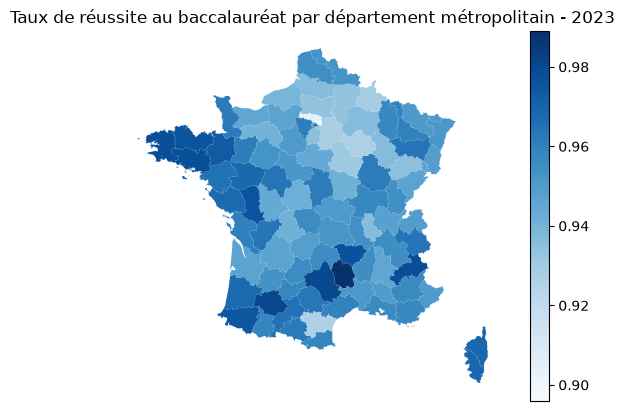

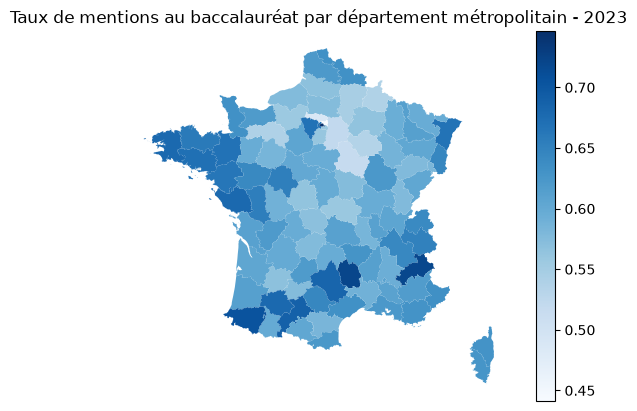

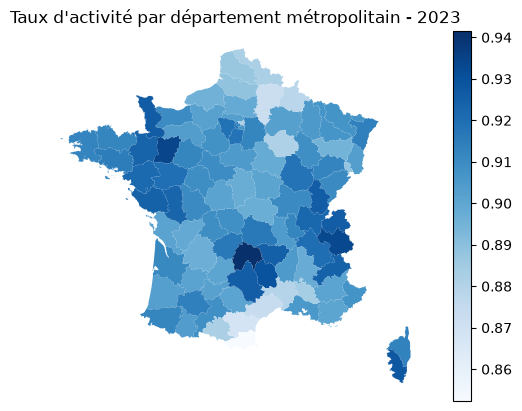

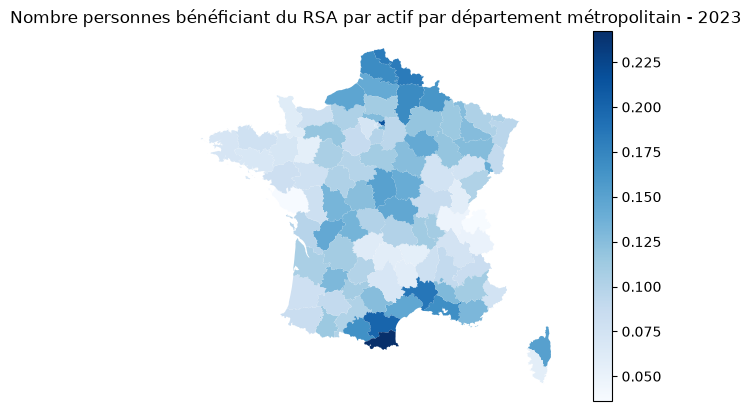

In [25]:
graph_réussite = france_metro.plot(
    column="Taux de réussite",
    legend=True,
    cmap="Blues",
)
graph_réussite.set_axis_off()
graph_réussite.set_title("Taux de réussite au baccalauréat par département métropolitain - 2023")

print(graph_réussite)

graph_mentions = france_metro.plot(
    column="Taux de mentions",
    legend=True,
    cmap="Blues",
)
graph_mentions.set_axis_off()
graph_mentions.set_title("Taux de mentions au baccalauréat par département métropolitain - 2023")

print(graph_mentions)

graph_activité = france_metro.plot(
    column="Taux d'activité",
    legend=True,
    cmap="Blues",
)
graph_activité.set_axis_off()
graph_activité.set_title("Taux d'activité par département métropolitain - 2023")

print(graph_activité)

graph_rsa = france_metro.plot(
    column="Nombre personnes bénéficiant du RSA par actif",
    legend=True,
    cmap="Blues",
)
graph_rsa.set_axis_off()
graph_rsa.set_title("Nombre personnes bénéficiant du RSA par actif par département métropolitain - 2023")

print(graph_rsa)